# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [1]:
!pip install huggingface_hub

In [2]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import time
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [3]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data\zadanie-1\pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [4]:
train_path = DATA_DIR / "pendigits" / "pendigits.tra"
test_path = DATA_DIR / "pendigits" / "pendigits.tes"

dane_train = pd.read_csv(train_path, header=None)
dane_test = pd.read_csv(test_path, header=None)

dane_train.head()

# zestaw danych służy do rozpoznawania cyfr (od 0 do 9) pisanych odręcznie.
# każdy wiersz tabeli to 1 narysowana cyfra. W zbiorze treningowym mamy 7494 narysowanych cyfr.
# cechy (Kolumny 0-15): system próbkował ruch rysika rejestrujac 8 pkt w przestrzeni (wspolrzedne x, y - łącznie 16 cech.
# wartosci wspolrzednych znormalizowane przestrzennie do zakresu od 0 do 100.
# zmienna docelowa (Kolumna 16) - faktyczna cyfra - to co model chce nam przewidziec


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,47,100,27,81,57,37,26,0,0,23,56,53,100,90,40,98,8
1,0,89,27,100,42,75,29,45,15,15,37,0,69,2,100,6,2
2,0,57,31,68,72,90,100,100,76,75,50,51,28,25,16,0,1
3,0,100,7,92,5,68,19,45,86,34,100,45,74,23,67,0,4
4,0,67,49,83,100,100,81,80,60,60,40,40,33,20,47,0,1


In [5]:
# Sprawdzenie czy w danych brakuje jakichkolwiek wartości (tzw. Null/NaN).
# Wynik '0' oznacza, że dane są kompletne.
braki = dane_train.isnull().sum().sum()
print(f"Braki danych w train: {braki}")

# Sprawdzenie powtarzających się wierszy (identycznych rysunków).
# Wynik '0' oznacza brak powtórzeń, co zapobiega sztucznemu zawyżaniu skuteczności modelu.
duplikaty = dane_train.duplicated().sum()
print(f"Duplikaty w train: {duplikaty}")

Braki danych w train: 0
Duplikaty w train: 0


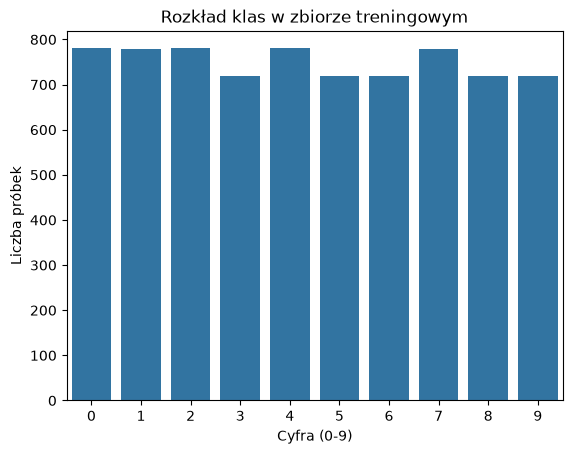

In [6]:
# Generowanie wykresu słupkowego dla kolumny o indeksie 16 (zmienna docelowa).
# Służy sprawdzeniu, czy zbiór jest zbalansowany

sns.countplot(x=dane_train[16])
plt.title("Rozkład klas w zbiorze treningowym")
plt.xlabel("Cyfra (0-9)")
plt.ylabel("Liczba próbek")
plt.show()

In [7]:
dane_train.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
count,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000
mean,37.384307,84.679343,40.005604,82.889512,50.878303,65.044436,51.471844,44.599680,57.129971,34.069122,61.417401,35.782092,54.699760,35.800774,46.813718,28.565386,4.430878
std,33.322024,16.848420,26.256025,19.638582,34.927201,27.377341,30.680075,30.659478,33.680340,27.459989,37.130762,27.495836,22.599781,33.223611,41.531794,35.811094,2.876981
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,76.000000,20.000000,70.000000,17.000000,48.000000,28.000000,22.000000,30.000000,7.000000,25.000000,12.000000,41.000000,7.000000,0.000000,0.000000,2.000000
50%,31.000000,89.000000,39.000000,89.000000,56.000000,71.000000,54.000000,42.000000,60.000000,33.000000,74.000000,32.000000,53.000000,28.000000,39.000000,8.000000,4.000000
75%,61.000000,100.000000,58.000000,100.000000,81.000000,86.000000,75.000000,65.000000,88.000000,55.000000,98.000000,57.000000,69.000000,48.000000,100.000000,51.000000,7.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,9.000000


In [8]:
#PRZYGOTOWANIE DANYCH
# Oddzielenie cech od zmiennej docelowej.

X_train = dane_train.iloc[:, :-1] 

y_train = dane_train.iloc[:, -1]  

# Analogiczny podział dla zbioru testowego.
X_test = dane_test.iloc[:, :-1]
y_test = dane_test.iloc[:, -1]

print("Kształt X_train:", X_train.shape)
print("Kształt y_train:", y_train.shape)

Kształt X_train: (7494, 16)
Kształt y_train: (7494,)


------- WNIOSKI ------- 

Stan danych: Zbiór jest czysty, nie zawiera braków danych ani duplikatów, nie trzeba np czyszcić wierszy.

Rozkład klas: Zbiór jest zbalansowany, a każda z 10 klas reprezentowana jest przez zbliżoną liczbę próbek (między 700 a 800). Dzięki temu nie trzeba stosować technik oversamplingu i można wykorzystać metrykę Accuracy do ostatecznej oceny modeli.

Uzasadnienie preprocessingu: Z funkcji describe() wynika, że cechy przyjmują wartości w zakresie od 0 do 100. Ponieważ średnie i odchylenia standardowe różnią się w zależności od punktu współrzędnych, wskazane jest zastosowanie standaryzacji (np. StandardScaler w pipeline), aby algorytmy oparte na dystansach (jak KNN) traktowały każdą cechę równoważnie.


## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Definiujemy pipeline dla modelu bazowego
baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()), # StandardScaler jest tu opcjonalny, ale nie zaszkodzi
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

# Sprawdzamy skuteczność za pomocą walidacji krzyżowej na zbiorze treningowym
# Argument cv=5 oznacza, że dzielimy dane na 5 części i trenujemy/testujemy 5 razy.
baseline_results = cross_validate(baseline_pipeline, X_train, y_train, cv=5, scoring="accuracy")

print(f"Średnia skuteczność modelu bazowego (Accuracy): {baseline_results['test_score'].mean():.4f}")

Średnia skuteczność modelu bazowego (Accuracy): 0.1041


Model bazowy pełni funkcję "najprostszego punktu odniesienia". Wykorzystany DummyClassifier ze strategią most_frequent przewiduje zawsze tę klasę, która występuje najczęściej w zbiorze treningowym. Ponieważ nasz zbiór jest zbalansowany i posiada 10 klas, trafność losowego zgadywania wynosi około 10%, co zgadza się z wynikiem (Accuracy 0.1041). Każdy prawdziwy model uczenia maszynowego musi osiągnąć wynik znacznie wyższy, aby uznać jego zastosowanie za celowe.

In [10]:
from sklearn.linear_model import LogisticRegression

# Pipeline dla regresji logistycznej
# Ustawiamy max_iter na większą wartość, jeśli standardowa (100) będzie zgłaszać błędy zbieżności
log_reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

log_reg_results = cross_validate(log_reg_pipeline, X_train, y_train, cv=5, scoring="accuracy")
print(f"Średnia skuteczność Regresji Logistycznej: {log_reg_results['test_score'].mean():.4f}")

Średnia skuteczność Regresji Logistycznej: 0.9617


Jest to klasyczna metoda statystyczna służąca do klasyfikacji. Poszukuje ona liniowych granic decyzyjnych między klasami (tu: między poszczególnymi cyframi). Ponieważ opiera się na wyliczaniu wag dla poszczególnych cech, jest bardzo szybka, ale może mieć problemy, jeśli relacje w danych są wysoce nieliniowe. Wymaga standaryzacji cech.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

# Pipeline dla KNN
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier())
])

# Definiujemy siatkę parametrów do sprawdzenia
param_grid = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11]
}

# GridSearchCV automatycznie stosuje walidację krzyżową na zbiorze X_train. 
# dba o to, by skaler był uczony tylko na wewnętrznych zestawach treningowych.
grid_search = GridSearchCV(knn_pipeline, param_grid, cv=5, scoring="accuracy")

# Uruchamiamy proces przeszukiwania
grid_search.fit(X_train, y_train)

print(f"Najlepsze hiperparametry KNN: {grid_search.best_params_}")
print(f"Skuteczność najlepszego modelu KNN na walidacji krzyżowej: {grid_search.best_score_:.4f}")

# Zapisujemy najlepszy model KNN do użycia w fazie C
best_knn_model = grid_search.best_estimator_

Najlepsze hiperparametry KNN: {'classifier__n_neighbors': 3}
Skuteczność najlepszego modelu KNN na walidacji krzyżowej: 0.9943


Algorytm klasycznego uczenia maszynowego oparty na dystansach. Dla każdej nowej próbki (cyfry) szuka k najbliższych sąsiadów w przestrzeni cech (zbiorze treningowym) i przypisuje jej taką klasę, jaka dominuje wśród tych sąsiadów. Jest bardzo wrażliwy na skalę danych, dlatego użycie StandardScaler jest tu absolutnie konieczne.

In [12]:
from sklearn.ensemble import RandomForestClassifier

# Pipeline dla Random Forest
rf_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(random_state=42))
])

# Siatka parametrów do strojenia
param_grid_rf = {
    "classifier__n_estimators": [50, 100, 200], # Liczba drzew w lesie
    "classifier__max_depth": [None, 10, 20]     # Maksymalna głębokość drzewa
}

grid_search_rf = GridSearchCV(rf_pipeline, param_grid_rf, cv=5, scoring="accuracy")
grid_search_rf.fit(X_train, y_train)

print(f"Najlepsze hiperparametry Random Forest: {grid_search_rf.best_params_}")
print(f"Skuteczność najlepszego modelu Random Forest na walidacji krzyżowej: {grid_search_rf.best_score_:.4f}")

# Zapisujemy najlepszy model Random Forest
best_rf_model = grid_search_rf.best_estimator_

Najlepsze hiperparametry Random Forest: {'classifier__max_depth': 20, 'classifier__n_estimators': 50}
Skuteczność najlepszego modelu Random Forest na walidacji krzyżowej: 0.9921


Zespół wielu drzew decyzyjnych. Każde drzewo uczy się na losowej próbce danych, dzieląc przestrzeń cech z wykorzystaniem prostych reguł "jeśli-to". Wynik końcowy to "głosowanie" wszystkich drzew. Model ten potrafi wychwycić skomplikowane, nieliniowe zależności i z natury nie wymaga standaryzacji danych. Jest jednak najbardziej złożony i potencjalnie najdroższy obliczeniowo.

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

--- Ewaluacja modelu: Baseline (Dummy) ---
Accuracy na zbiorze testowym: 0.1038
Czas predykcji na zbiorze testowym: 2.15 ms


--- Ewaluacja modelu: Regresja Logistyczna ---
Accuracy na zbiorze testowym: 0.9160
Czas predykcji na zbiorze testowym: 2.08 ms


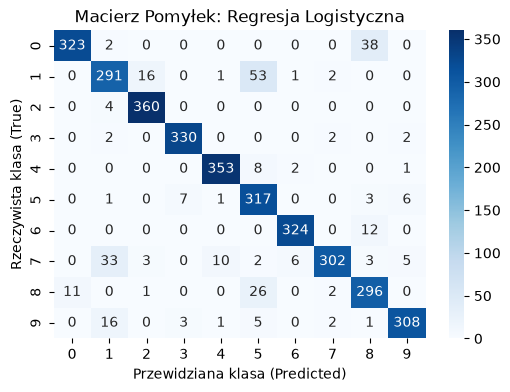



--- Ewaluacja modelu: k-Nearest Neighbors ---
Accuracy na zbiorze testowym: 0.9748
Czas predykcji na zbiorze testowym: 62.47 ms


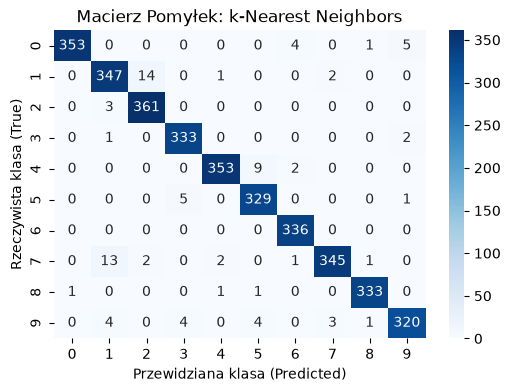



--- Ewaluacja modelu: Random Forest ---
Accuracy na zbiorze testowym: 0.9628
Czas predykcji na zbiorze testowym: 29.50 ms


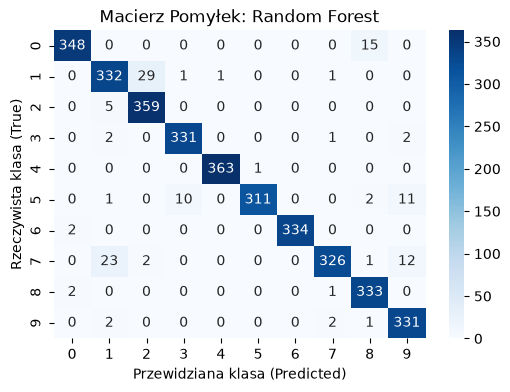

In [13]:
# Ręczne wytrenowanie modeli na pełnym zbiorze treningowym
baseline_pipeline.fit(X_train, y_train)
log_reg_pipeline.fit(X_train, y_train)

models = {
    "Baseline (Dummy)": baseline_pipeline,
    "Regresja Logistyczna": log_reg_pipeline,
    "k-Nearest Neighbors": best_knn_model,
    "Random Forest": best_rf_model
}

# Inicjalizacja słowników na wyniki
test_accuracies = {}
inference_times = {}

for name, model in models.items():
    print(f"--- Ewaluacja modelu: {name} ---")
    
    # Rozpoczęcie pomiaru czasu
    start_time = time.time()
    
    # Przewidywanie klas dla zbioru testowego
    y_pred = model.predict(X_test)
    
    # Zakończenie pomiaru czasu i zapis wyniku w milisekundach
    end_time = time.time()
    inference_time = (end_time - start_time) * 1000 
    inference_times[name] = inference_time
    
    # Obliczenie Accuracy
    acc = accuracy_score(y_test, y_pred)
    test_accuracies[name] = acc
    
    print(f"Accuracy na zbiorze testowym: {acc:.4f}")
    print(f"Czas predykcji na zbiorze testowym: {inference_time:.2f} ms")
    
    # Generowanie macierzy pomyłek dla bardziej złożonych modeli
    if name != "Baseline (Dummy)":
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title(f"Macierz Pomyłek: {name}")
        plt.xlabel('Przewidziana klasa (Predicted)')
        plt.ylabel('Rzeczywista klasa (True)')
        plt.show()
        
    print("\n")

--- WNIOSKI KOŃCOWE (Porównanie modeli) ---

1. Skuteczność na oficjalnym zbiorze testowym:
       Model bazowy (Dummy) zadziałał zgodnie z oczekiwaniami, uzyskując wynik bliski losowemu zgadywaniu (~10% Accuracy).
       Prosta Regresja Logistyczna rozpoznała poprawnie 91.6% odręcznie pisanych cyfr.
       Random Forest osiągnął 96.2%
       k-Nearest Neighbors (k-NN) okazał się bezkonkurencyjny z dokładnością rzędu 97.4%.

2. Analiza błędów (Macierze pomyłek):
Najsłabsza w zestawieniu Regresja Logistyczna ma wyraźne problemy z konkretnymi, podobnymi do siebie ruchami rysika. Na przykład cyfrę "1" aż 53 razy błędnie zidentyfikowała jako "5", a z cyfrą "7" myliła się 33 razy. Lepsze modele niemal całkowicie zniwelowały te konkretne problemy. Najlepszy model (k-NN) wciąż najczęściej, bo 14 razy, mylił "1" z "2" (oraz 13 razy na odwrót), co prawdopodobnie wynika ze specyficznego sposobu zapisywania tych znaków przez niektórych użytkowników.

3. Porównanie kosztów (Złożoność i Parametry vs Czas Inferencji):
     Regresja Logistyczna reprezentuje niski koszt obliczeniowy. Model po wyuczeniu zapamiętał jedynie niewielką macierz wag (10 klas × 16 cech = 160 parametrów plus wyrazy wolne). Przekłada się to na błyskawiczny czas predykcji, wynoszący zaledwie ~3 ms na całym zbiorze testowym.

      W Random Forest czas inferencji był około 8-krotnie dłuższy niż regresji (~26 ms).

      k-NN technicznie rzecz biorąc jest modelem nieparametrycznym, co oznacza, że podczas uczenia zapamiętuje po prostu cały zbiór danych treningowych. Skutkuje to najwyższymi kosztami w fazie predykcji – dla każdej nowej próbki model musi obliczyć odległość od tysięcy zapamiętanych punktów. Czas inferencji okazał się tutaj najdłuższy (~75 ms).

4. Czy wzrost złożoności jest wart uzyskanej poprawy?
Odpowiedź zależy od kontekstu wdrożenia.
Jeśli budujemy aplikację mobilną z bardzo ograniczoną pamięcią, która musi działać bez opóźnień na tanim procesorze w czasie rzeczywistym, prosta i niezwykle szybka Regresja Logistyczna mogłaby stanowić akceptowalny kompromis (91.6% skuteczności).
Jednakże, poprawa dokładności rozpoznawania pisma z 91.6% (Regresja) na 97.4% (k-NN) to gigantyczny skok jakości dla użytkownika końcowego. Mimo iż czas predykcji wydłużył się ponad dwudziestokrotnie (z 3 ms do 75 ms), w skali interakcji człowiek-komputer (np. odczytywania wypełnionego formularza) 75 milisekund to nadal wartość nieodczuwalna dla oka. Zatem w typowym scenariuszu komercyjnym zwiększenie złożoności modelu jest tu absolutnie warte uzyskanej poprawy i zdecydowanie w większości przypadków algorytm k-Nearest Neighbors byłby najlepszym zastosowaniem.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.

Źródła:
Oficjalna dokumentacja biblioteki scikit-learn.

Dokumentacja bibliotek pandas i seaborn.

Książka, którą wykorzystujemy na zajęciach z Uczenia maszynowego dostępna na stronie: https://www.statlearning.com/

Do wsparcia w rozwiązywaniu błędów w kodzie (np. problemów z iteracją w nowej wersji seaborn czy NotFittedError przy ewaluacji pipeline'u) oraz do ustrukturyzowania wniosków teoretycznych wykorzystałam model językowy Google Gemini.